In [35]:
from typing import TypedDict, Annotated, Literal, Optional
import operator, uuid, json
from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.postgres.aio import AsyncPostgresSaver   # nodes are async, so the graph runs via .ainvoke

import psycopg
from psycopg.rows import dict_row
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI
import os
from langchain_mcp_adapters.client import MultiServerMCPClient
from dotenv import load_dotenv

import mcp.client.stdio as mcp_stdio
from composio import Composio
import asyncio
import sys
from pathlib import Path
load_dotenv()
from IPython.display import Image,display

from typing import TypedDict, Literal, Annotated
import operator

In [36]:
if not os.getenv("COMPOSIO_API_KEY"):
    raise ValueError("COMPOSIO_API_KEY is not set")
if not os.getenv("COMPOSIO_USER_ID"):
    raise ValueError("COMPOSIO_USER_ID is not set")

composio = Composio(api_key=os.getenv("COMPOSIO_API_KEY"))

WEATHER_API_KEY = os.getenv("OPENWEATHER_API_KEY")
if WEATHER_API_KEY:
    print("True")
    
KLAVIS_GMAIL_MCP_URL = os.environ["KLAVIS_GMAIL_MCP_URL"]
KLAVIS__SLACK_MCP_URL = os.environ["KLAVIS_SLACK_MCP_URL"]
KLAVIS_MCP_TOKEN = os.environ["KLAVIS_MCP_TOKEN"]

True


In [37]:
mcp_stdio.stdio_client.__wrapped__.__defaults__ = (open(os.devnull, "w"),)

In [38]:
from composio import Composio
session = composio.create(
    user_id=os.getenv("COMPOSIO_USER_ID"),
    toolkits=['calendly']
)

url = session.mcp.url

In [39]:
WEATHER_MCP_SERVER = (Path.cwd().parent / "agents" / "mcp_servers" / "weather_server.py").resolve()
assert WEATHER_MCP_SERVER.exists(), f"missing {WEATHER_MCP_SERVER}"


client = MultiServerMCPClient(
    {
        "openweather": {
            "transport": "stdio",
            "command": sys.executable,
            "args": [str(WEATHER_MCP_SERVER)],
            "env": {
                "OPENWEATHER_API_KEY": WEATHER_API_KEY
            },
        },
        "Klavis-strata": {
            "url": KLAVIS_GMAIL_MCP_URL,
            "transport": "streamable_http",
            "headers": {
                "Authorization": f"Bearer {KLAVIS_MCP_TOKEN}"
            }
        },
        "calendly-agent":{
            "transport":"streamable_http",
            "url":session.mcp.url,
            "headers":{
                "x-api-key":os.getenv("COMPOSEIO_API_KEY")
            }
        },
        "Slack-mcp":{
            "url": KLAVIS__SLACK_MCP_URL,
            "transport":"streamable_http",
            "headers":{
                "Authorization":f"Bearer {KLAVIS_MCP_TOKEN}"
            }
        },
    }
)

In [40]:
tools = client.get_tools()
tools = await tools  # resolve coroutine returned by client.get_tools()
print(f"Loaded {len(tools)} MCP tools:")
for t in tools:
    print(f"- {t.name}")
tools

Loaded 30 MCP tools:
- get_current_weather
- gmail_send_email
- gmail_draft_email
- gmail_read_email
- gmail_search_emails
- gmail_modify_email
- gmail_delete_email
- gmail_batch_modify_emails
- gmail_batch_delete_emails
- gmail_get_email_attachments
- gmail_search_contacts
- COMPOSIO_GET_TOOL_SCHEMAS
- COMPOSIO_MANAGE_CONNECTIONS
- COMPOSIO_MULTI_EXECUTE_TOOL
- COMPOSIO_REMOTE_BASH_TOOL
- COMPOSIO_REMOTE_WORKBENCH
- COMPOSIO_SEARCH_TOOLS
- slack_user_list_channels
- slack_get_channel_history
- slack_get_thread_replies
- slack_invite_users_to_channel
- slack_list_users
- slack_user_get_info
- slack_user_search_messages
- slack_user_post_message
- slack_user_reply_to_thread
- slack_user_add_reaction
- slack_bot_post_message
- slack_bot_reply_to_thread
- slack_bot_add_reaction


[StructuredTool(name='get_current_weather', description='Get current weather for a city name or zip/postal code via OpenWeather.\n\n    location: a city name (e.g. "Lahore", "Paris,FR") or a zip/postal code (e.g. "10001")\n    units: "standard" (Kelvin), "metric" (Celsius, m/s), or "imperial" (Fahrenheit, mph)\n    ', args_schema={'properties': {'location': {'title': 'Location', 'type': 'string'}, 'units': {'default': 'metric', 'enum': ['standard', 'metric', 'imperial'], 'title': 'Units', 'type': 'string'}}, 'required': ['location'], 'title': 'get_current_weatherArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x000002299638A8E0>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x00000229AD693F60>),
 StructuredTool(name='gmail_send_email', description='Sends a new email. You MUST NOT assume the emails unless they are explicitly provided. You may use gmail_search_contacts tool to fin

In [41]:
async def get_agent_tools(mcp_client: MultiServerMCPClient) -> dict:
    """Pulls the Slack tools plus Composio's Tool Router meta-tools, keyed
    by name. calendly-agent's MCP session doesn't expose Calendly actions
    directly -- it exposes Composio's generic router (search -> read
    schema -> execute), so an LLM agent discovers/calls the right Calendly
    tool at runtime instead of us hardcoding a tool_slug we can't verify
    without a live session. See create_scheduling_link/check_booking.
    """
    all_tools = await mcp_client.get_tools()
    tools_by_name = {t.name: t for t in all_tools}

    required = [
        "slack_user_post_message",
        "slack_user_list_channels",
        "COMPOSIO_SEARCH_TOOLS",
        "COMPOSIO_GET_TOOL_SCHEMAS",
        "COMPOSIO_MULTI_EXECUTE_TOOL",
        "COMPOSIO_MANAGE_CONNECTIONS",
    ]
    missing = [name for name in required if name not in tools_by_name]
    if missing:
        raise RuntimeError(f"missing expected MCP tools: {missing}")

    return {name: tools_by_name[name] for name in required}


agent_tools = await get_agent_tools(client)
slack_user_post_message = agent_tools["slack_user_post_message"]         # notify_slack_node -- posts the booking alert
slack_user_list_channels = agent_tools["slack_user_list_channels"]       # resolves SLACK_CHANNEL_NAME -> channel_id once
composio_search_tools = agent_tools["COMPOSIO_SEARCH_TOOLS"]             # Calendly agent -- find the right tool
composio_get_tool_schemas = agent_tools["COMPOSIO_GET_TOOL_SCHEMAS"]     # Calendly agent -- read its exact arguments
composio_multi_execute_tool = agent_tools["COMPOSIO_MULTI_EXECUTE_TOOL"] # Calendly agent -- call it
composio_manage_connections = agent_tools["COMPOSIO_MANAGE_CONNECTIONS"] # diagnostic -- verify calendly is actually connected

In [43]:
# What this graph carries. customer_ids is optional -- when empty/omitted,
# check_bookings scans every already-invited customer instead of a specific
# batch. bookings/notified/saved are separate accumulators (rather than one
# list mutated in place) so a partial failure at any stage is visible: e.g.
# if Slack posting fails for one booking, it simply won't appear in
# `notified`, and save_booking_node (which only saves what's in `notified`)
# will leave it unsaved -- it gets picked up and re-notified next run
# instead of silently getting marked booked without ever alerting the team.
class NotifyState(TypedDict):
    customer_ids: list[str]
    bookings: Annotated[list[dict], operator.add]
    notified: Annotated[list[dict], operator.add]
    saved: Annotated[list[dict], operator.add]
    errors: Annotated[list[str], operator.add]

In [44]:
async def ensure_notify_columns() -> None:
    """Idempotent migration for the one column this graph needs beyond what
    Run A's ensure_tracking_table already creates on `tracking`
    (db/schema.sql). Safe to call on every notebook run.
    """
    ddl = "ALTER TABLE tracking ADD COLUMN IF NOT EXISTS scheduled_at TIMESTAMPTZ;"
    async with await psycopg.AsyncConnection.connect(os.environ["DATABASE_URL"]) as conn:
        async with conn.cursor() as cur:
            await cur.execute(ddl)


await ensure_notify_columns()

In [45]:
# DB helpers against Run A's `tracking` table (db/schema.sql), joined to
# `customers` for the details the Slack message needs. Every function takes
# an already-open psycopg AsyncConnection (row_factory=dict_row), opened
# once per node call -- same pattern as Run A's sender_agent.

async def get_awaiting_booking(conn, customer_ids: list[str] | None = None) -> list[dict]:
    """Already-invited customers (nudge_count > 0, still 'interested') who
    haven't booked a Calendly slot yet -- candidates for check_bookings_node
    to poll.
    """
    query = """
        SELECT t.customer_id, t.thread_id, t.storm_context,
               c.first_name, c.last_name, c.email, c.phone, c.city, c.state,
               c.roof_material, c.roof_age_years
        FROM tracking t
        JOIN customers c ON c.customer_id = t.customer_id
        WHERE t.status = 'interested' AND t.nudge_count > 0
    """
    params: tuple = ()
    if customer_ids:
        query += " AND t.customer_id = ANY(%s)"
        params = (customer_ids,)

    async with conn.cursor() as cur:
        await cur.execute(query, params)
        return await cur.fetchall()


async def mark_booked(conn, customer_id: int, scheduled_at: str | None) -> None:
    async with conn.cursor() as cur:
        await cur.execute(
            """UPDATE tracking
               SET status = 'booked', scheduled_at = %s::timestamptz
               WHERE customer_id = %s""",
            (scheduled_at, customer_id),
        )

In [46]:
import re
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.errors import GraphRecursionError

# calendly-agent's MCP session only exposes Composio's generic Tool Router
# (COMPOSIO_SEARCH_TOOLS / COMPOSIO_GET_TOOL_SCHEMAS / COMPOSIO_MULTI_EXECUTE_TOOL)
# -- not fixed Calendly tools. Those three meta-tools' own schemas include
# "thought"/"current_step" fields, which only make sense for an LLM driving
# them step by step. So rather than guessing a Calendly tool_slug and its
# argument names (unverifiable without a live session), a small ReAct agent
# does the search -> read-schema -> execute loop itself.
composio_agent_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
composio_agent = create_react_agent(
    composio_agent_llm,
    [composio_search_tools, composio_get_tool_schemas, composio_multi_execute_tool],
)

COMPOSIO_AGENT_SYSTEM_PROMPT = """You have three Composio Tool Router tools: COMPOSIO_SEARCH_TOOLS \
(find the right tool for a task), COMPOSIO_GET_TOOL_SCHEMAS (read a tool's exact argument schema), and \
COMPOSIO_MULTI_EXECUTE_TOOL (call it). Only use tools from the Calendly toolkit. Use CALENDLY_GET_USER \
for the current user, never the deprecated CALENDLY_GET_CURRENT_USER.

1. Search for the tool(s) that match the task -- some tasks need more than one call (e.g. you may need
   the current user's URI before you can filter another call by it).
2. Fetch each tool's schema before calling it -- never guess argument names.
3. Execute with correctly-shaped arguments.
4. Reply with ONLY a single JSON object in the exact shape requested -- no prose, no markdown fences.

If COMPOSIO_MULTI_EXECUTE_TOOL returns an error (auth failure, no connection, tool not found, missing
required argument, etc.), do NOT retry it and do NOT search again. Immediately reply with
{"error": "<the tool's exact error message>"}. A failed execution is a final answer, not a signal to try
something else."""


def _parse_agent_json(messages: list) -> dict:
    text = messages[-1].content
    if isinstance(text, list):  # some providers return content blocks instead of a plain string
        text = "".join(b.get("text", "") for b in text if isinstance(b, dict))
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if not match:
        raise RuntimeError(f"Calendly agent returned no JSON: {text!r}")
    return json.loads(match.group(0))


async def _run_composio_agent(task: str, timeout: float = 90.0) -> dict:
    """Runs the ReAct loop with a hard wall-clock timeout and a low
    recursion_limit, so a stuck/looping agent (e.g. retrying
    COMPOSIO_MULTI_EXECUTE_TOOL against a missing required argument) fails
    fast with a clear error instead of hanging the whole graph run
    indefinitely -- observed this exact failure mode against check_booking's
    "list events" call, which needs the current user's URI first.
    """
    try:
        result = await asyncio.wait_for(
            composio_agent.ainvoke(
                {
                    "messages": [
                        SystemMessage(content=COMPOSIO_AGENT_SYSTEM_PROMPT),
                        HumanMessage(content=task),
                    ]
                },
                config={"recursion_limit": 12},
            ),
            timeout=timeout,
        )
    except asyncio.TimeoutError as exc:
        raise RuntimeError(
            f"Calendly agent did not respond within {timeout}s -- likely stuck retrying "
            "COMPOSIO_MULTI_EXECUTE_TOOL."
        ) from exc
    except GraphRecursionError as exc:
        raise RuntimeError(
            "Calendly agent hit its 12-step recursion limit without converging -- likely looping on "
            "COMPOSIO_MULTI_EXECUTE_TOOL."
        ) from exc

    parsed = _parse_agent_json(result["messages"])
    if "error" in parsed:
        raise RuntimeError(f"Calendly agent task failed: {parsed['error']}")
    return parsed


async def check_booking(invitee_email: str) -> dict | None:
    """Checks whether `invitee_email` has booked a Calendly event yet.
    Returns None if not booked, else {"scheduled_at": "<ISO 8601 or None>"}.
    """
    parsed = await _run_composio_agent(
        f"Check whether {invitee_email} has booked/scheduled a Calendly event. First call CALENDLY_GET_USER "
        f"to get the current user's URI (Calendly's list-events tool requires it to filter by organizer) -- "
        f"then list scheduled events filtered by that user and invitee_email={invitee_email}. "
        f"Reply with JSON: {{\"booked\": true/false, \"scheduled_at\": \"<ISO 8601 start time or null>\"}}."
    )
    return {"scheduled_at": parsed.get("scheduled_at")} if parsed.get("booked") else None

C:\Users\Dell\AppData\Local\Temp\ipykernel_26820\3814754445.py:14: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  composio_agent = create_react_agent(


In [47]:
# Slack helpers. SLACK_CHANNEL_NAME is resolved to a channel_id once (Slack's
# post tools take an ID, not a name) and cached for the rest of the run.
SLACK_CHANNEL_NAME = "leads-only"
_slack_channel_id_cache: str | None = None


async def get_slack_channel_id() -> str:
    global _slack_channel_id_cache
    if _slack_channel_id_cache:
        return _slack_channel_id_cache

    # The channel_name server-side filter turned out unreliable once types
    # includes private_channel (confirmed empty even for a channel the
    # connected identity is actually in) -- fetch the full list instead and
    # match client-side. Cheap: this workspace only has a handful of
    # channels, and the result is cached after the first call anyway.
    raw = await slack_user_list_channels.ainvoke({
        "types": "public_channel,private_channel",
        "limit": 200,
    })
    payload = json.loads(raw[0]["text"])
    channels = payload if isinstance(payload, list) else payload.get("channels") or []

    exact = [c for c in channels if c.get("name", "").lower() == SLACK_CHANNEL_NAME.lower()]
    if not exact:
        raise RuntimeError(
            f"could not find Slack channel {SLACK_CHANNEL_NAME!r} among {[c.get('name') for c in channels]}"
        )

    _slack_channel_id_cache = exact[0]["id"]
    return _slack_channel_id_cache


def format_booking_message(booking: dict) -> str:
    storm = booking.get("storm_context") or {}
    return (
        f":calendar: *New inspection booked* -- {booking['first_name']} {booking['last_name']}\n"
        f"*When:* {booking.get('scheduled_at') or 'time TBD'}\n"
        f"*Contact:* {booking['email']}" + (f" | {booking['phone']}" if booking.get("phone") else "") + "\n"
        f"*Address:* {booking['city']}, {booking['state']}\n"
        f"*Roof:* {booking.get('roof_material', 'unknown')}, ~{booking.get('roof_age_years', '?')} yrs old\n"
        f"*Storm context:* {storm.get('condition_text', 'n/a')}, {storm.get('wind_mph', '?')} mph, "
        f"{storm.get('date', 'n/a')}"
    )


async def notify_slack(booking: dict) -> None:
    channel_id = await get_slack_channel_id()
    await slack_user_post_message.ainvoke({
        "channel_id": channel_id,
        "text": format_booking_message(booking),
    })

In [48]:
async def check_bookings_node(state: NotifyState):
    """Polls Calendly (via the Composio agent) for customers already invited
    in RunB (interested + nudge_count > 0) who haven't booked yet. Doesn't
    touch the DB -- just collects who's newly booked, in state, for the next
    two nodes.
    """
    bookings: list[dict] = []
    errors: list[str] = []

    async with await psycopg.AsyncConnection.connect(
        os.environ["DATABASE_URL"], row_factory=dict_row, autocommit=True
    ) as conn:
        rows = await get_awaiting_booking(conn, state.get("customer_ids"))

        for row in rows:
            try:
                result = await check_booking(row["email"])
                if result is None:
                    continue  # not booked yet
                bookings.append({**row, "scheduled_at": result["scheduled_at"]})
            except Exception as exc:
                errors.append(f"{row['customer_id']}: booking check failed - {exc}")

    return {"bookings": bookings, "errors": errors}


async def notify_slack_node(state: NotifyState):
    """Posts one Slack message per newly-booked customer with meeting time,
    client details, and full storm context. Only bookings that post
    successfully move on to save_booking_node -- one that fails here stays
    'interested' in the DB and gets picked up (and re-notified) next run,
    instead of silently being marked booked without ever alerting the team.
    """
    notified: list[dict] = []
    errors: list[str] = []

    for booking in state.get("bookings", []):
        try:
            await notify_slack(booking)
            notified.append(booking)
        except Exception as exc:
            errors.append(f"{booking['customer_id']}: slack notify failed - {exc}")

    return {"notified": notified, "errors": errors}


async def save_booking_node(state: NotifyState):
    """Persists status='booked' + scheduled_at only for bookings that were
    actually notified in Slack -- the last step, per the check -> notify ->
    save order.
    """
    saved: list[dict] = []
    errors: list[str] = []

    async with await psycopg.AsyncConnection.connect(
        os.environ["DATABASE_URL"], row_factory=dict_row, autocommit=True
    ) as conn:
        for booking in state.get("notified", []):
            try:
                await mark_booked(conn, booking["customer_id"], booking["scheduled_at"])
                saved.append({"customer_id": booking["customer_id"]})
            except Exception as exc:
                errors.append(f"{booking['customer_id']}: db save failed - {exc}")

    return {"saved": saved, "errors": errors}

In [49]:
# AsyncPostgresSaver is an async context manager; entered manually (rather than
# `async with`) so the connection stays open across the notebook's cells.
checkpointer_cm = AsyncPostgresSaver.from_conn_string(os.environ["DATABASE_URL"])
checkpointer = await checkpointer_cm.__aenter__()
await checkpointer.setup()

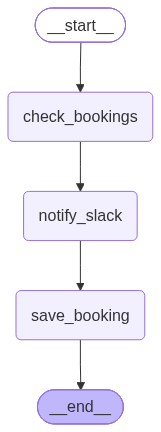

In [50]:
notify_builder = StateGraph(NotifyState)
notify_builder.add_node("check_bookings", check_bookings_node)
notify_builder.add_node("notify_slack", notify_slack_node)
notify_builder.add_node("save_booking", save_booking_node)
notify_builder.add_edge(START, "check_bookings")
notify_builder.add_edge("check_bookings", "notify_slack")
notify_builder.add_edge("notify_slack", "save_booking")
notify_builder.add_edge("save_booking", END)

graph_c = notify_builder.compile(checkpointer=checkpointer)  # your Postgres checkpointer
display(Image(graph_c.get_graph().draw_mermaid_png()))

In [51]:
RUN_C_THREAD_ID = str(uuid.uuid4())
config = {"configurable": {"thread_id": RUN_C_THREAD_ID}}

# Leave customer_ids empty to scan every already-invited customer, or pass
# specific customer_ids to limit this run to a subset (e.g. your own test
# inbox's customer_id). Nothing here is simulated -- this really checks
# Calendly, really posts to the #leads-only Slack channel, and really marks
# tracking.status = 'booked'. Only run against a live DATABASE_URL with rows
# you're prepared to have posted about.
result = await graph_c.ainvoke({"customer_ids": []}, config)

print("bookings found:", result["bookings"])
print("notified:", result["notified"])
print("saved:", result["saved"])
if result.get("errors"):
    print("errors:", result["errors"])

bookings found: [{'customer_id': 402, 'thread_id': '19faaf8a312f8a6f', 'storm_context': {'city': 'Dallas', 'date': '2026-07-28', 'wind_mph': 45.0, 'condition_text': 'thunderstorm with heavy rain'}, 'first_name': 'Muhammad', 'last_name': 'Ali', 'email': 'sirajcharter1@gmail.com', 'phone': '(214) 555-0187', 'city': 'Dallas', 'state': 'TX', 'roof_material': 'metal', 'roof_age_years': 8, 'scheduled_at': '2026-07-30T07:00:00.000000Z'}]
notified: [{'customer_id': 402, 'thread_id': '19faaf8a312f8a6f', 'storm_context': {'city': 'Dallas', 'date': '2026-07-28', 'wind_mph': 45.0, 'condition_text': 'thunderstorm with heavy rain'}, 'first_name': 'Muhammad', 'last_name': 'Ali', 'email': 'sirajcharter1@gmail.com', 'phone': '(214) 555-0187', 'city': 'Dallas', 'state': 'TX', 'roof_material': 'metal', 'roof_age_years': 8, 'scheduled_at': '2026-07-30T07:00:00.000000Z'}]
saved: [{'customer_id': 402}]


In [52]:
raw = await slack_user_list_channels.ainvoke({"types": "public_channel,private_channel", "limit": 200})
channels = json.loads(raw[0]["text"])
print(channels)

{'ok': True, 'channels': [{'id': 'C0BBWHKDZ1D', 'name': 'all-elevensoftwares'}, {'id': 'C0BCC3PM5RQ', 'name': 'general'}, {'id': 'C0BCDT9KSFK', 'name': 'new-channel'}, {'id': 'C0BCDUCLA65', 'name': 'modeaquariums'}, {'id': 'C0BD6AJK2QG', 'name': 'social'}, {'id': 'C0BDBP4HCK0', 'name': 'leads-only'}], 'summary': {'total_returned': 6, 'message': 'Found 6 channels.'}, 'response_metadata': {'next_cursor': ''}}
